# Imports

In [2]:
import random
import time
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from PIL import Image
from torchvision import datasets, transforms
from torchvision.transforms import InterpolationMode
from torch.utils.data import DataLoader, random_split


device = "cuda" if torch.cuda.is_available() else "cpu"

print(device)

cuda


# Fixando as seeds:

In [3]:
seed = 15

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Carregando o dataset (PASCAL VOC 2012)

In [5]:
def transform_voc(image, mask):
    image = transforms.functional.resize(image, [160, 240], interpolation=InterpolationMode.BILINEAR)
    mask = transforms.functional.resize(mask, [160, 240], interpolation=InterpolationMode.NEAREST)

    image = transforms.ToTensor()(image)
    mask = torch.from_numpy(np.array(mask, dtype=np.int64).copy())

    return image, mask

train_data = datasets.VOCSegmentation(root="./data", year="2012", image_set="train", download=True, transforms=transform_voc)

test_data = datasets.VOCSegmentation(root="./data", year="2012", image_set="val", download=True, transforms=transform_voc)

train_size = int(0.8 * len(train_data))
val_size = len(train_data) - train_size

train_data, validation_data = random_split(train_data, [train_size, val_size], generator=torch.Generator().manual_seed(seed))

batch_size = 8

train_data = DataLoader(train_data, batch_size=batch_size, shuffle=True)
validation_data = DataLoader(validation_data, batch_size=batch_size, shuffle=False)
test_data = DataLoader(test_data, batch_size=batch_size, shuffle=False)

100%|██████████| 2.00G/2.00G [01:15<00:00, 26.4MB/s]


# Modelo U-Net:

## Definindo o modelo (U-Net)

In [4]:

# Classe para auxiliar a definicao da classe do modelo (U-Net)
class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


class UNET(nn.Module):

    def __init__(self, in_channels=3, out_channels=21, features=(64, 128, 256, 512), use_skip_connections=True):
        super().__init__()

        self.use_skip_connections = use_skip_connections
        self.downs = nn.ModuleList()
        self.ups = nn.ModuleList()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        for feature in features:
            self.downs.append(DoubleConv(in_channels, feature))
            in_channels = feature

        self.bottleneck = DoubleConv(features[-1], features[-1] * 2)

        for feature in reversed(features):
            self.ups.append(nn.ConvTranspose2d(feature * 2, feature, kernel_size=2, stride=2))

            if use_skip_connections:
                self.ups.append(DoubleConv(feature * 2, feature))
            else:
                self.ups.append(DoubleConv(feature, feature))

        self.final_conv = nn.Conv2d(features[0], out_channels, kernel_size=1)

    def forward(self, x):
        skip_connections = []

        for down in self.downs:
            x = down(x)

            if self.use_skip_connections:
                skip_connections.append(x)

            x = self.pool(x)

        x = self.bottleneck(x)
        skip_connections = skip_connections[::-1]

        for idx in range(0, len(self.ups), 2):
            x = self.ups[idx](x)

            if self.use_skip_connections:
                skip = skip_connections[idx // 2]

                if x.shape != skip.shape:
                    x = TF.resize(x, size=skip.shape[2:])

                x = torch.cat((skip, x), dim=1)

            x = self.ups[idx + 1](x)

        return self.final_conv(x)

    def avaliar(self, loader, loss_fn, device):
        self.eval()

        total_loss = 0.0
        total_correct = 0
        total_pixels = 0

        with torch.no_grad():
            for images, masks in loader:
                images = images.to(device)
                masks = masks.to(device)

                outputs = self(images)
                loss = loss_fn(outputs, masks)

                total_loss += loss.item()

                predictions = outputs.argmax(dim=1)
                valid_pixels = masks != 255

                total_correct += ((predictions == masks) & valid_pixels).sum().item()
                total_pixels += valid_pixels.sum().item()

        mean_loss = total_loss / len(loader)
        accuracy = total_correct / total_pixels if total_pixels > 0 else 0.0

        return mean_loss, accuracy

    def treinar(self, train_loader, val_loader, num_epochs=30, learning_rate=1e-4, patience=3, delta=0.01, device="cpu"):
        self.to(device)

        loss_fn = nn.CrossEntropyLoss(ignore_index=255)
        optimizer = optim.Adam(self.parameters(), lr=learning_rate)

        train_losses = []
        train_accuracies = []
        val_losses = []
        val_accuracies = []

        best_val_loss = float("inf")
        epochs_without_improvement = 0

        start_time = time.time()

        for epoch in range(num_epochs):
            self.train()

            total_loss = 0.0
            total_correct = 0
            total_pixels = 0

            for images, masks in train_loader:
                images = images.to(device)
                masks = masks.to(device)

                outputs = self(images)
                loss = loss_fn(outputs, masks)

                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

                total_loss += loss.item()

                predictions = outputs.argmax(dim=1)
                valid_pixels = masks != 255

                total_correct += ((predictions == masks) & valid_pixels).sum().item()
                total_pixels += valid_pixels.sum().item()

            train_loss = total_loss / len(train_loader)
            train_accuracy = total_correct / total_pixels if total_pixels > 0 else 0.0

            val_loss, val_accuracy = self.avaliar(val_loader, loss_fn, device)

            train_losses.append(train_loss)
            train_accuracies.append(train_accuracy)
            val_losses.append(val_loss)
            val_accuracies.append(val_accuracy)

            if val_loss < best_val_loss - delta:
                best_val_loss = val_loss
                epochs_without_improvement = 0
            else:
                epochs_without_improvement += 1

            if epochs_without_improvement >= patience:
                print("Early stopping.")
                break

        training_time = time.time() - start_time
        print(f"Tempo total de treinamento: {training_time:.2f} segundos")

        return train_losses, train_accuracies, val_losses, val_accuracies, training_time


## Treinando:

In [ ]:
model = UNET(in_channels=3, out_channels=21, use_skip_connections=True)

train_losses, train_accuracies, val_losses, val_accuracies, training_time = model.treinar(train_data, validation_data, num_epochs=30, learning_rate=1e-4, patience=3, delta=0.01, device=device)

## Visualizando os resultados do treinamento:

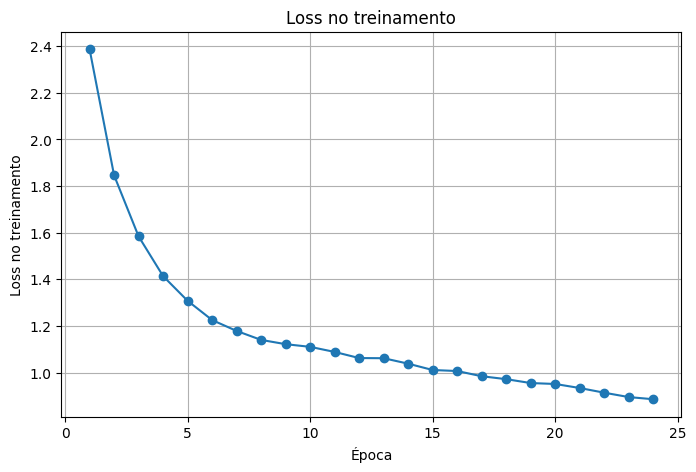

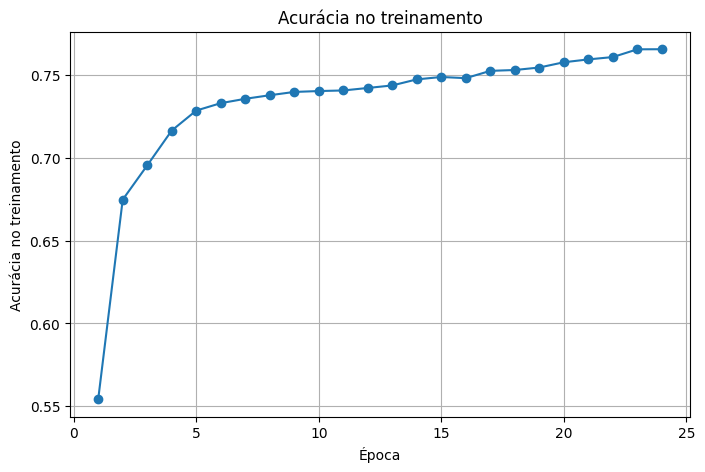

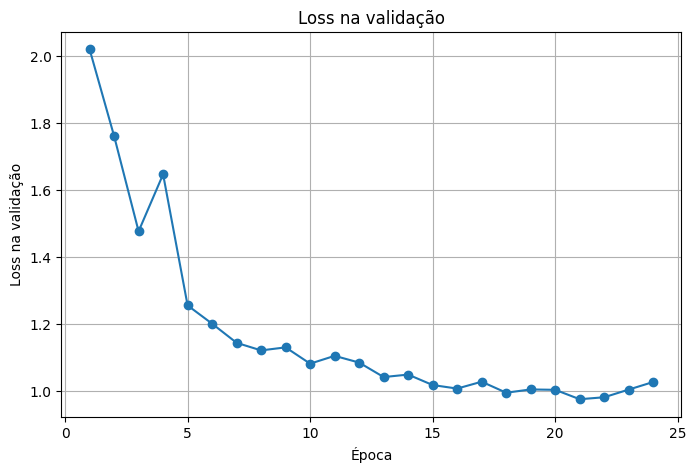

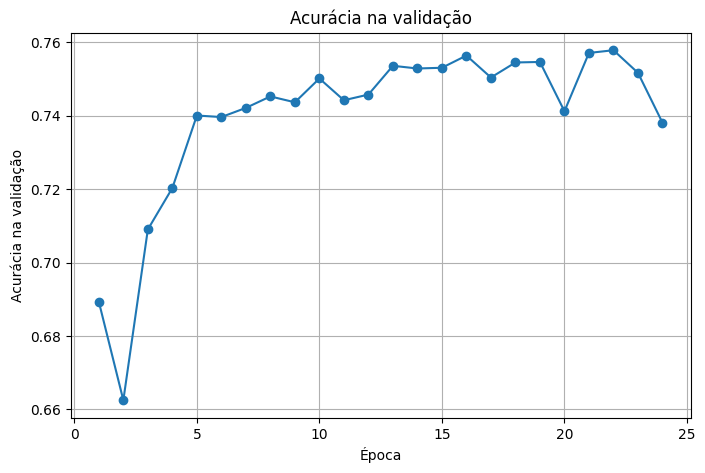

In [12]:
def gerar_grafico(x, y, descricao):
    plt.figure(figsize=(8, 5))
    plt.plot(x, y, marker="o")
    plt.xlabel("Época")
    plt.ylabel(descricao)
    plt.title(descricao)
    plt.grid(True)
    plt.show()

epocas = range(1, len(train_losses) + 1)

gerar_grafico(epocas, train_losses, "Loss no treinamento")
gerar_grafico(epocas, train_accuracies, "Acurácia no treinamento")
gerar_grafico(epocas, val_losses, "Loss na validação")
gerar_grafico(epocas, val_accuracies, "Acurácia na validação")

## Teste:

In [13]:
loss_fn = nn.CrossEntropyLoss(ignore_index=255)

test_loss, test_accuracy = model.avaliar(test_data, loss_fn, device)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy (%): {test_accuracy * 100:.2f}%")

Test Loss: 1.0577
Test Accuracy: 0.7270
Test Accuracy (%): 72.70%


## Visualizando o teste:

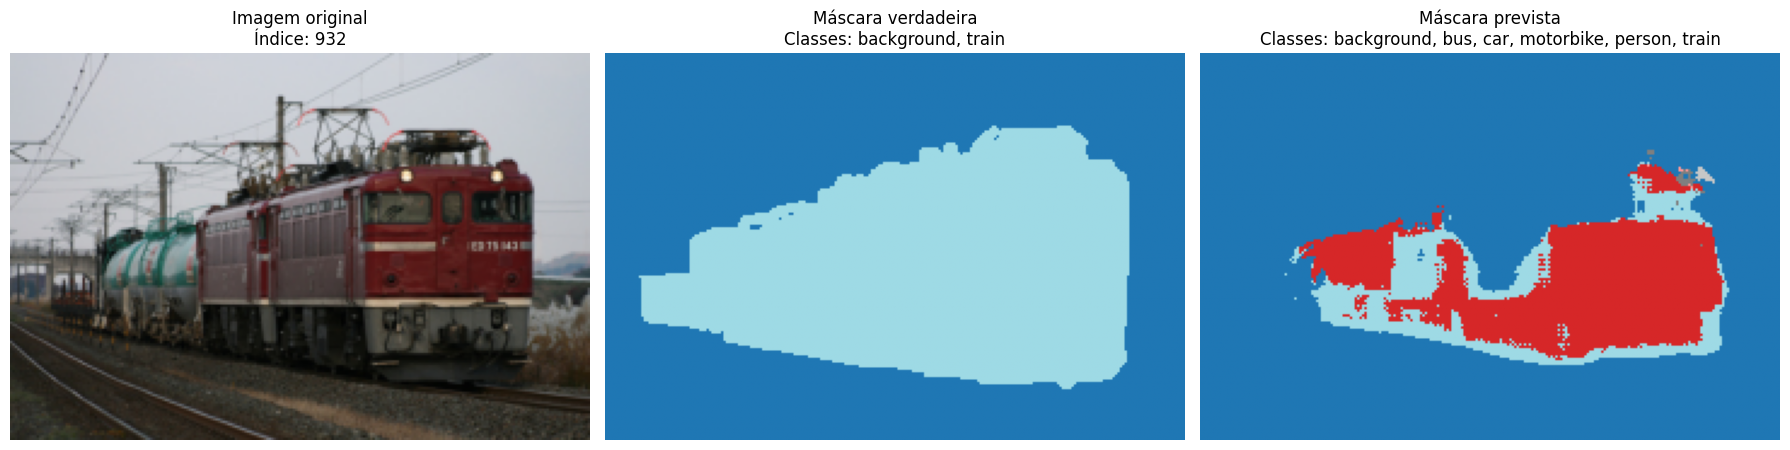

In [47]:
model.eval()

idx = random.randrange(len(test_data.dataset))
image_tensor, mask_tensor = test_data.dataset[idx]

with torch.no_grad():
    outputs = model(image_tensor.unsqueeze(0).to(device))
    prediction = outputs.argmax(dim=1).squeeze(0).cpu().numpy()

image = image_tensor.permute(1, 2, 0).numpy()
mask = mask_tensor.numpy()

class_names = {
    0: "background",
    1: "aeroplane",
    2: "bicycle",
    3: "bird",
    4: "boat",
    5: "bottle",
    6: "bus",
    7: "car",
    8: "cat",
    9: "chair",
    10: "cow",
    11: "diningtable",
    12: "dog",
    13: "horse",
    14: "motorbike",
    15: "person",
    16: "pottedplant",
    17: "sheep",
    18: "sofa",
    19: "train",
    20: "tvmonitor",
    255: "ignore"
}

predicted_classes = np.unique(prediction)
true_classes = np.unique(mask)

predicted_names = []

for class_id in predicted_classes:
    if class_id != 255:
        name = class_names.get(int(class_id), f"unknown ({class_id})")
        predicted_names.append(name)

true_names = []

for class_id in true_classes:
    if class_id != 255:
        name = class_names.get(int(class_id), f"unknown ({class_id})")
        true_names.append(name)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(image)
axes[0].set_title(f"Imagem original\nÍndice: {idx}")

axes[1].imshow(mask, cmap="tab20", vmin=0, vmax=20)
axes[1].set_title("Máscara verdadeira\nClasses: " + ", ".join(true_names))

axes[2].imshow(prediction, cmap="tab20", vmin=0, vmax=20)
axes[2].set_title("Máscara prevista\nClasses: " + ", ".join(predicted_names))

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Modelo FCN simplificado

## Definindo o modelo:

In [6]:
class FCN(nn.Module):

    def __init__(self, in_channels=3, out_channels=21):
        super().__init__()

        self.conv1 = nn.Conv2d(in_channels, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)

        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        self.final_conv = nn.Conv2d(128, out_channels, kernel_size=1)

        self.upsample = nn.ConvTranspose2d(out_channels,out_channels,kernel_size=8,stride=8)

    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.pool(x)

        x = self.relu(self.conv2(x))
        x = self.pool(x)

        x = self.relu(self.conv3(x))
        x = self.pool(x)

        x = self.final_conv(x)
        x = self.upsample(x)

        return x

    def avaliar(self, loader, loss_fn, device):
        self.eval()

        total_loss = 0.0
        total_correct = 0
        total_pixels = 0

        with torch.no_grad():
            for images, masks in loader:
                images = images.to(device)
                masks = masks.to(device)

                outputs = self(images)
                loss = loss_fn(outputs, masks)

                total_loss += loss.item()

                predictions = outputs.argmax(dim=1)
                valid_pixels = masks != 255

                total_correct += ((predictions == masks) & valid_pixels).sum().item()
                total_pixels += valid_pixels.sum().item()

        mean_loss = total_loss / len(loader)
        accuracy = total_correct / total_pixels if total_pixels > 0 else 0.0

        return mean_loss, accuracy

    def treinar(self, train_loader, val_loader, num_epochs=30, learning_rate=1e-4, patience=3, delta=0.01, device="cpu"):
        self.to(device)

        loss_fn = nn.CrossEntropyLoss(ignore_index=255)
        optimizer = optim.Adam(self.parameters(), lr=learning_rate)

        train_losses = []
        train_accuracies = []
        val_losses = []
        val_accuracies = []

        best_val_loss = float("inf")
        epochs_without_improvement = 0

        start_time = time.time()

        for epoch in range(num_epochs):
            self.train()

            total_loss = 0.0
            total_correct = 0
            total_pixels = 0

            for images, masks in train_loader:
                images = images.to(device)
                masks = masks.to(device)

                outputs = self(images)
                loss = loss_fn(outputs, masks)

                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

                total_loss += loss.item()

                predictions = outputs.argmax(dim=1)
                valid_pixels = masks != 255

                total_correct += ((predictions == masks) & valid_pixels).sum().item()
                total_pixels += valid_pixels.sum().item()

            train_loss = total_loss / len(train_loader)
            train_accuracy = total_correct / total_pixels if total_pixels > 0 else 0.0

            val_loss, val_accuracy = self.avaliar(val_loader, loss_fn, device)

            train_losses.append(train_loss)
            train_accuracies.append(train_accuracy)
            val_losses.append(val_loss)
            val_accuracies.append(val_accuracy)


            if val_loss < best_val_loss - delta:
                best_val_loss = val_loss
                epochs_without_improvement = 0
            else:
                epochs_without_improvement += 1

            if epochs_without_improvement >= patience:
                print("Early stopping.")
                break

        training_time = time.time() - start_time

        print(f"Tempo total de treinamento: {training_time:.2f} segundos")

        return train_losses, train_accuracies, val_losses, val_accuracies, training_time


## Treinando:

In [ ]:

model_fcn = FCN(in_channels=3, out_channels=21)

fcn_train_losses, fcn_train_accuracies, fcn_val_losses, fcn_val_accuracies, fcn_training_time = model_fcn.treinar(train_data,validation_data,num_epochs=30,learning_rate=1e-4,patience=3,delta=0.01,device=device)


## Visualizando os resultados do treinamento:

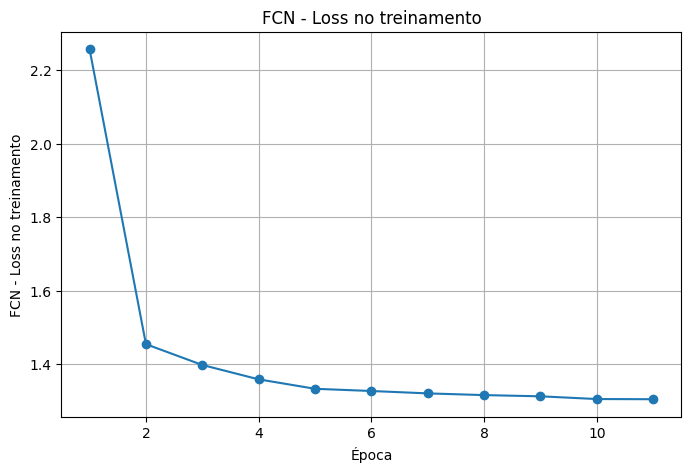

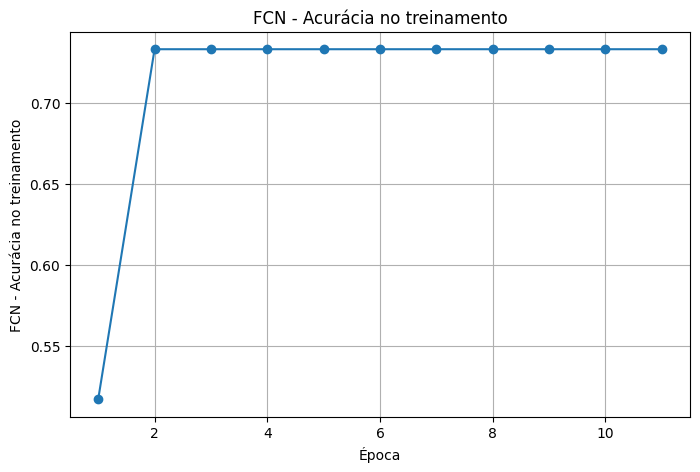

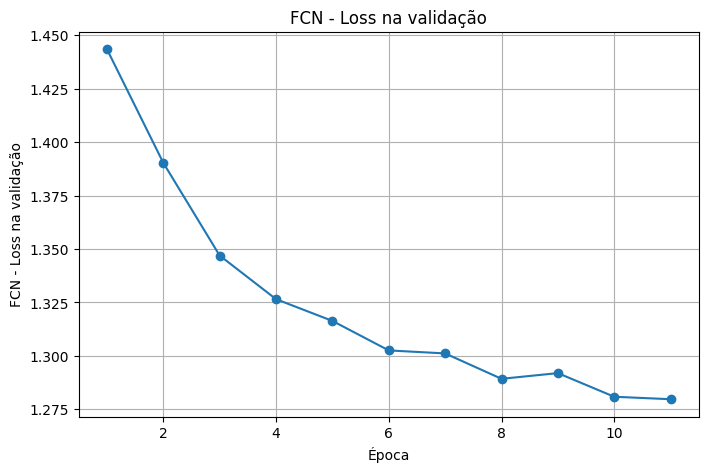

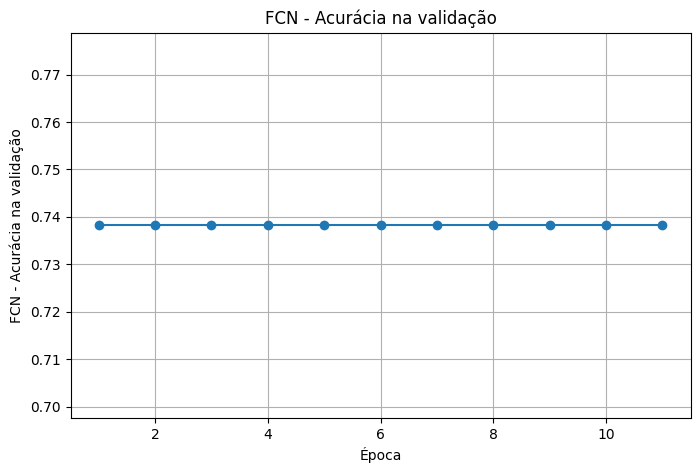

In [8]:
# definindo de novo so pra poder rodar esse aqui sem precisar rodar o da U-Net
def gerar_grafico(x, y, descricao):
    plt.figure(figsize=(8, 5))
    plt.plot(x, y, marker="o")
    plt.xlabel("Época")
    plt.ylabel(descricao)
    plt.title(descricao)
    plt.grid(True)
    plt.show()


epocas_fcn = range(1, len(fcn_train_losses) + 1)

gerar_grafico(epocas_fcn, fcn_train_losses, "FCN - Loss no treinamento")
gerar_grafico(epocas_fcn, fcn_train_accuracies, "FCN - Acurácia no treinamento")
gerar_grafico(epocas_fcn, fcn_val_losses, "FCN - Loss na validação")
gerar_grafico(epocas_fcn, fcn_val_accuracies, "FCN - Acurácia na validação")


## Teste:

In [9]:

loss_fn = nn.CrossEntropyLoss(ignore_index=255)

fcn_test_loss, fcn_test_accuracy = model_fcn.avaliar(test_data,loss_fn,device)

print(f"Test Loss: {fcn_test_loss:.4f}")
print(f"Test Accuracy: {fcn_test_accuracy:.4f}")
print(f"Test Accuracy (%): {fcn_test_accuracy * 100:.2f}%")
print(f"Tempo de treinamento: {fcn_training_time:.2f} segundos")


Test Loss: 1.3017
Test Accuracy: 0.7327
Test Accuracy (%): 73.27%
Tempo de treinamento: 137.34 segundos


## Visualizando o teste da FCN

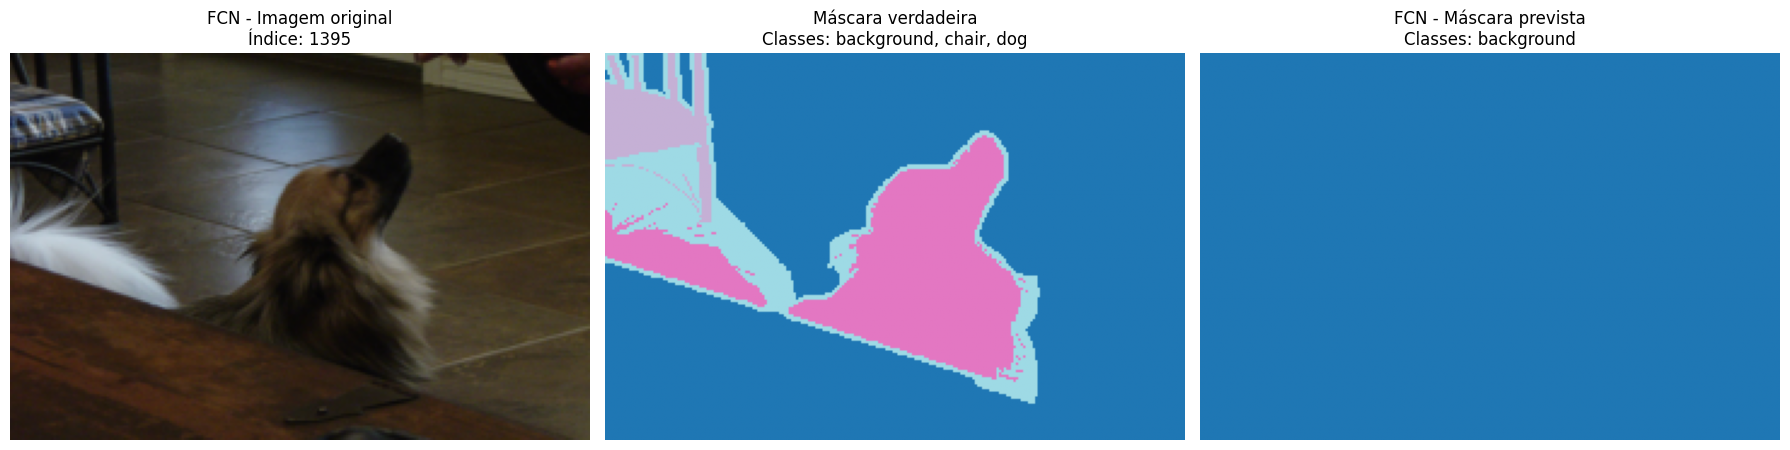

In [18]:
model_fcn.eval()

idx = random.randrange(len(test_data.dataset))
image_tensor, mask_tensor = test_data.dataset[idx]

with torch.no_grad():
    outputs = model_fcn(image_tensor.unsqueeze(0).to(device))
    prediction = outputs.argmax(dim=1).squeeze(0).cpu().numpy()

image = image_tensor.permute(1, 2, 0).numpy()
mask = mask_tensor.numpy()

class_names = {
    0: "background",
    1: "aeroplane",
    2: "bicycle",
    3: "bird",
    4: "boat",
    5: "bottle",
    6: "bus",
    7: "car",
    8: "cat",
    9: "chair",
    10: "cow",
    11: "diningtable",
    12: "dog",
    13: "horse",
    14: "motorbike",
    15: "person",
    16: "pottedplant",
    17: "sheep",
    18: "sofa",
    19: "train",
    20: "tvmonitor",
    255: "ignore"
}

predicted_classes = np.unique(prediction)
true_classes = np.unique(mask)

predicted_names = []

for class_id in predicted_classes:
    if class_id != 255:
        name = class_names.get(int(class_id), f"unknown ({class_id})")
        predicted_names.append(name)

true_names = []

for class_id in true_classes:
    if class_id != 255:
        name = class_names.get(int(class_id), f"unknown ({class_id})")
        true_names.append(name)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(image)
axes[0].set_title(f"FCN - Imagem original\nÍndice: {idx}")

axes[1].imshow(mask, cmap="tab20", vmin=0, vmax=20)
axes[1].set_title("Máscara verdadeira\nClasses: " + ", ".join(true_names))

axes[2].imshow(prediction, cmap="tab20", vmin=0, vmax=20)
axes[2].set_title("FCN - Máscara prevista\nClasses: " + ", ".join(predicted_names))

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()
